# PathSnap Review 1 Visualizations

This notebook generates the figures in the Review 1 report. It reads the local development exports, the original development GPS/road files, the archived Optuna trials and the fitted PathSnap scorer. Running the notebook loads the existing model and predicts on the 10 student-test trips. No fitting or hyperparameter search runs here.

Run from the project root or the notebooks directory. Use the dependencies in requirements-data.txt and requirements-models.txt and a Jupyter kernel in the same environment. For the saved-run results, use scikit-learn 1.7.2, LightGBM 4.7.0 and pandas 2.3.2. Prepare the local development exports and audit inventories using the commands in handoffs/01-data-and-features.md. Fetch the Git LFS model if the checkout contains only its pointer. Figure PNGs are written to runs/review1/figures by default.


In [1]:
import hashlib
from io import StringIO
import json
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.collections import LineCollection
from matplotlib.lines import Line2D

root = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / "pathsnap").is_dir() and (p / "requirements-models.txt").is_file()), None)
if root is None:
    raise FileNotFoundError("Open the notebook from inside the PathSnap repository.")
sys.path.insert(0, str(root))

from pathsnap.data.loading import load_trip
from pathsnap.data.reference_alignment import read_reference_route
from pathsnap.models.evaluation.metrics import evaluate
from pathsnap.models.features import add_context_features
from pathsnap.models.schema import FEATURE_ORDER, OBS_KEY, OBSERVATION_COLS
from pathsnap.models.training.scorer import CandidateScorer

def dataset_dir():
    for path in (root / "Student folder" / "Student folder", root / "data"):
        if (path / "train").is_dir() and (path / "student_test").is_dir():
            return path
    raise FileNotFoundError("Place the unzipped development dataset in Student folder/Student folder or data.")

raw = dataset_dir()
member1 = root / "runs" / "member1"
development = member1 / "development"
archive = root / "reports" / "model-experiments" / "results_archive"
figures = Path(os.environ.get("PATHSNAP_REVIEW1_FIGURES", root / "runs" / "review1" / "figures"))
figures.mkdir(parents=True, exist_ok=True)
blue, orange, teal, ink = "#22588D", "#CA6736", "#13776E", "#182C40"
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 10, "axes.titlesize": 12,
                     "axes.labelcolor": ink, "text.color": ink, "axes.edgecolor": "#A7B6C2",
                     "xtick.color": ink, "ytick.color": ink, "axes.spines.top": False,
                     "axes.spines.right": False, "savefig.facecolor": "white"})

def save_figure(fig, filename):
    fig.savefig(figures / filename, dpi=240, bbox_inches="tight", pad_inches=0.14)
    plt.show()
    plt.close(fig)

def read_split(split, table):
    files = sorted((development / split).glob(f"*/{table}.csv.gz"))
    expected = {"train": 80, "student_test": 10}[split]
    if len(files) != expected:
        raise FileNotFoundError(f"Expected {expected} {table} exports for {split}, found {len(files)}.")
    return pd.concat([pd.read_csv(file, dtype={"trip_id": str}) for file in files], ignore_index=True)


## Development data audit

Each marker represents one trip. The logarithmic axes make the largest graphs and longest GPS gaps visible. The GPS map uses projected metres and the supplied route for training trip 00000048.


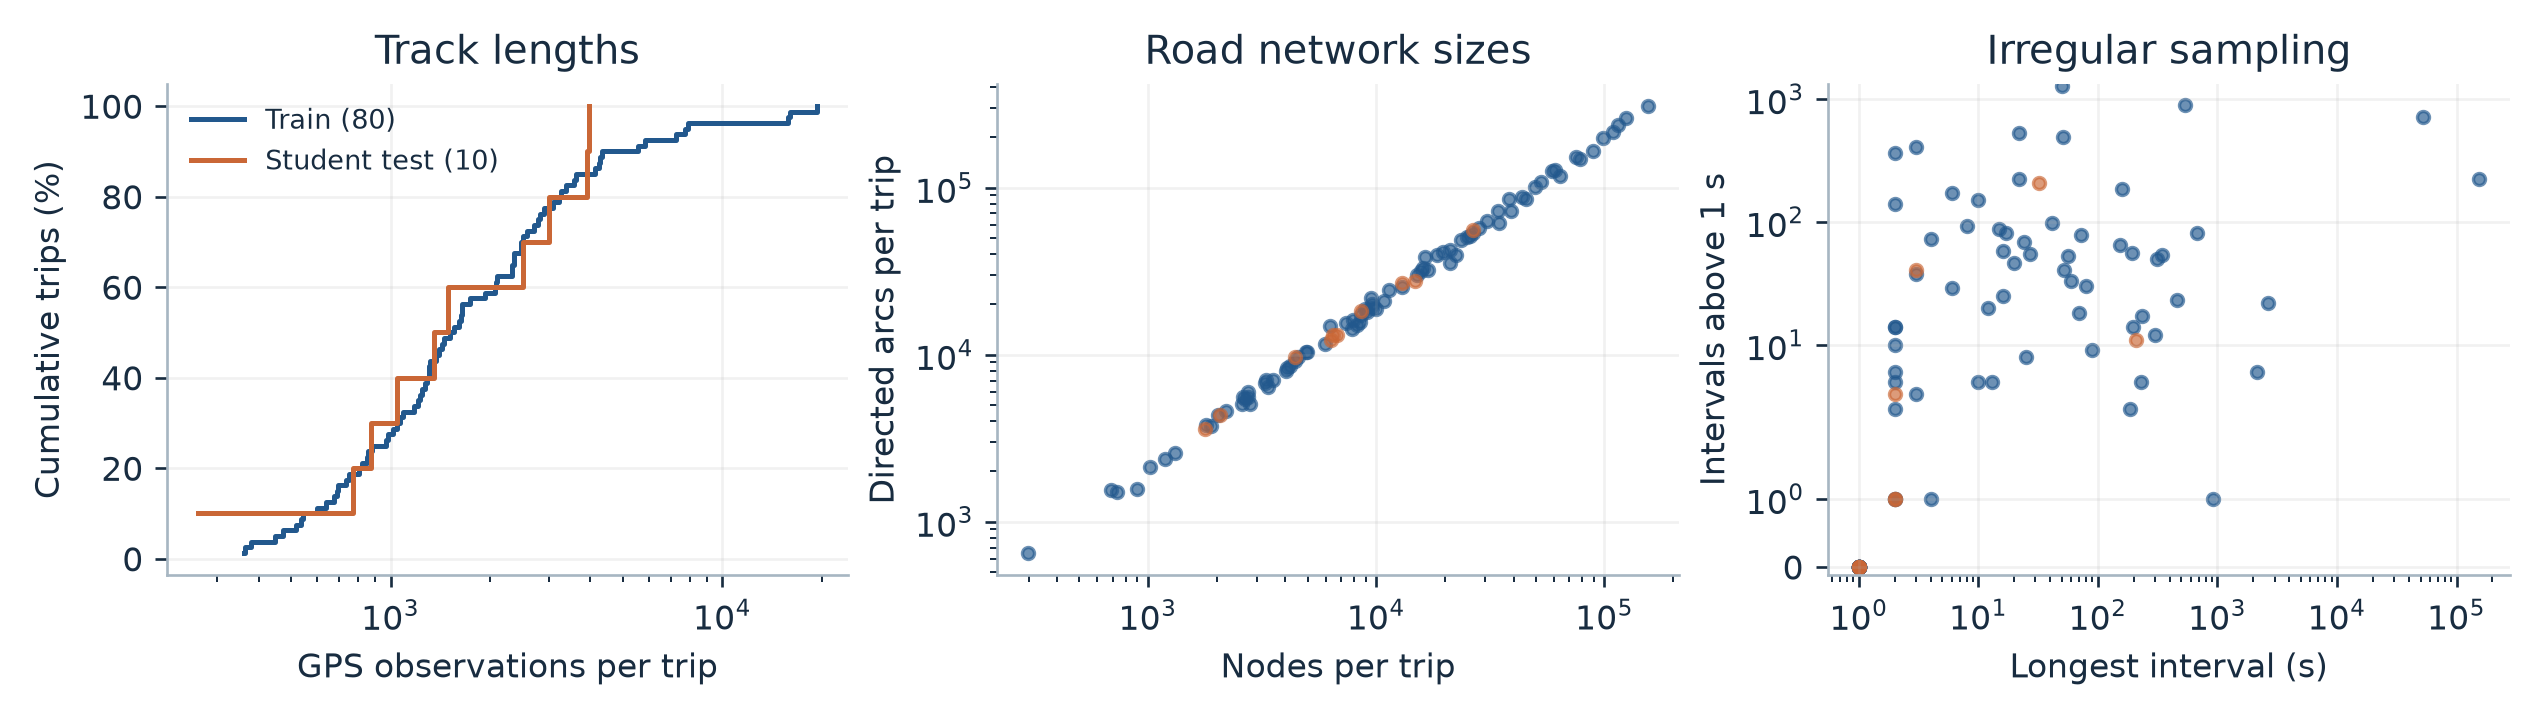

In [2]:
inventory = pd.concat([
    pd.read_csv(member1 / folder / "trip_inventory.csv", dtype={"trip_id": str})
    for folder in ("train-audit", "student-test-audit")
], ignore_index=True)
assert inventory["valid"].all() and len(inventory) == 90
fig, axes = plt.subplots(1, 3, figsize=(10.4, 2.8), layout="constrained")
for split, color, name in (("train", blue, "Train"), ("student_test", orange, "Student test")):
    group = inventory.loc[inventory["split"].eq(split)]
    ordered = group["gps_rows"].sort_values()
    axes[0].step(ordered, 100 * np.arange(1, len(group) + 1) / len(group),
                 where="post", color=color, label=f"{name} ({len(group)})")
    axes[1].scatter(group["nodes"], group["arcs"], color=color, s=13, alpha=0.66)
    axes[2].scatter(group["max_gap_s"], group["gaps_gt_1s"], color=color, s=13, alpha=0.66)
axes[0].set(title="Track lengths", xlabel="GPS observations per trip", ylabel="Cumulative trips (%)", xscale="log")
axes[1].set(title="Road network sizes", xlabel="Nodes per trip", ylabel="Directed arcs per trip",
            xscale="log", yscale="log")
axes[2].set(title="Irregular sampling", xlabel="Longest interval (s)", ylabel="Intervals above 1 s",
            xscale="log", yscale="symlog")
axes[2].set_ylim(bottom=-0.12)
axes[0].legend(frameon=False, fontsize=8)
for ax in axes:
    ax.grid(alpha=0.17)
save_figure(fig, "development_eda.png")


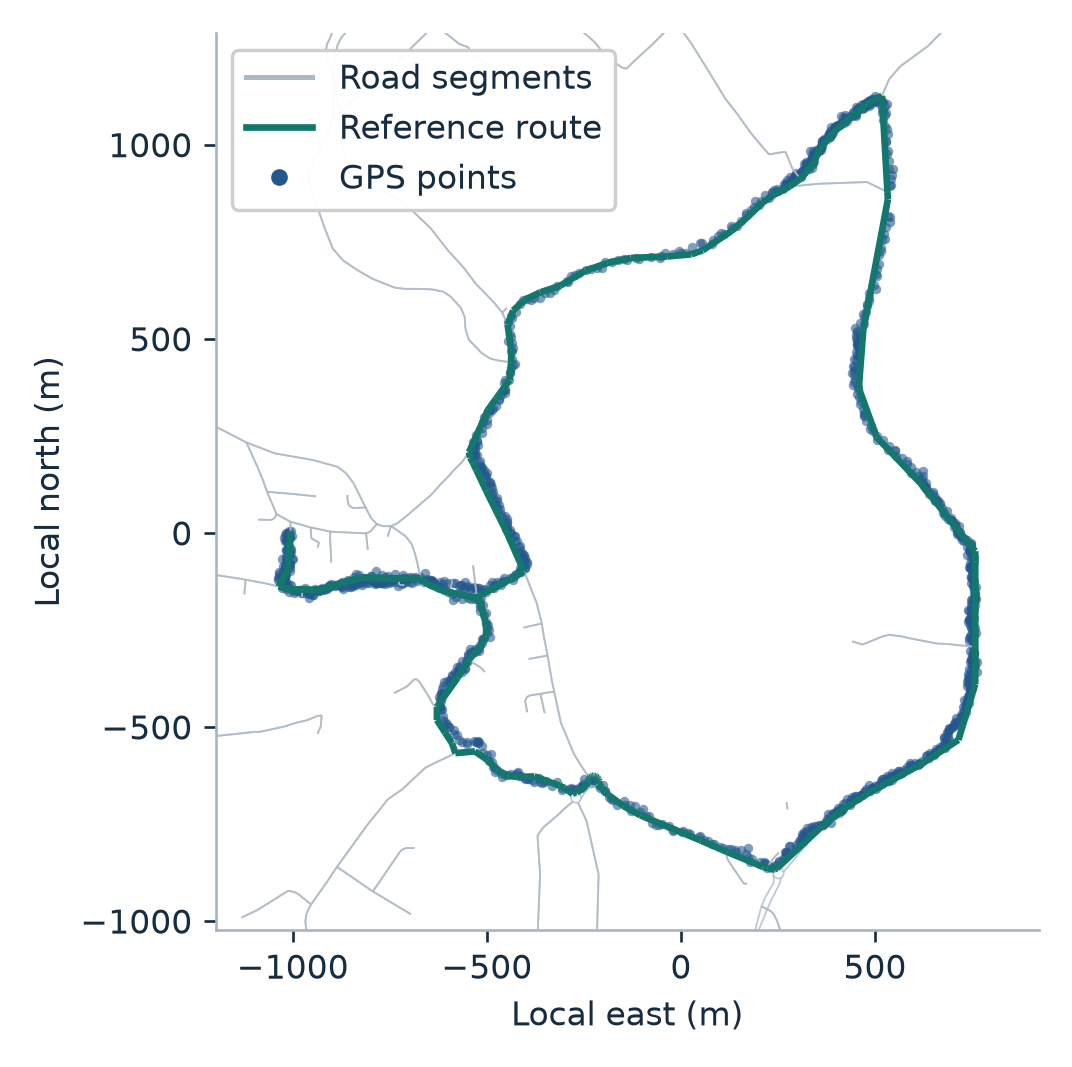

In [3]:
trip_dir = raw / "train" / "00000048"
trip = load_trip(trip_dir)
route = read_reference_route(trip, trip_dir)
segments = trip.node_xy[trip.arc_nodes]
low = trip.observation_xy.min(axis=0) - 160
high = trip.observation_xy.max(axis=0) + 160
nearby = ((segments.max(axis=1) >= low) & (segments.min(axis=1) <= high)).all(axis=1)
fig, ax = plt.subplots(figsize=(8.2, 4.25), layout="constrained")
ax.add_collection(LineCollection(segments[nearby], colors="#ACB8C3", linewidths=0.55, alpha=0.75))
ax.add_collection(LineCollection(segments[route], colors=teal, linewidths=2.0))
ax.scatter(*trip.observation_xy.T, s=8, color=blue, alpha=0.58, linewidths=0)
ax.set(xlim=(low[0], high[0]), ylim=(low[1], high[1]), aspect="equal",
       xlabel="Local east (m)", ylabel="Local north (m)")
ax.legend(handles=[
    Line2D([], [], color="#ACB8C3", label="Road segments"),
    Line2D([], [], color=teal, linewidth=2, label="Reference route"),
    Line2D([], [], color=blue, marker="o", markersize=4, linestyle="", label="GPS points"),
], loc="upper left", framealpha=0.96)
save_figure(fig, "gps_geometry.png")


## Feature correlations and scatter plot

Correlations are candidate-weighted. They use pairwise available raw feature values before imputation or scaling and include all training candidates. Pearson measures linear association and Spearman measures rank association. The scatter uses aligned, labelled training candidates with valid heading, sampled by class for readability. The two samples deliberately use equal sizes, so point density does not represent class prevalence.


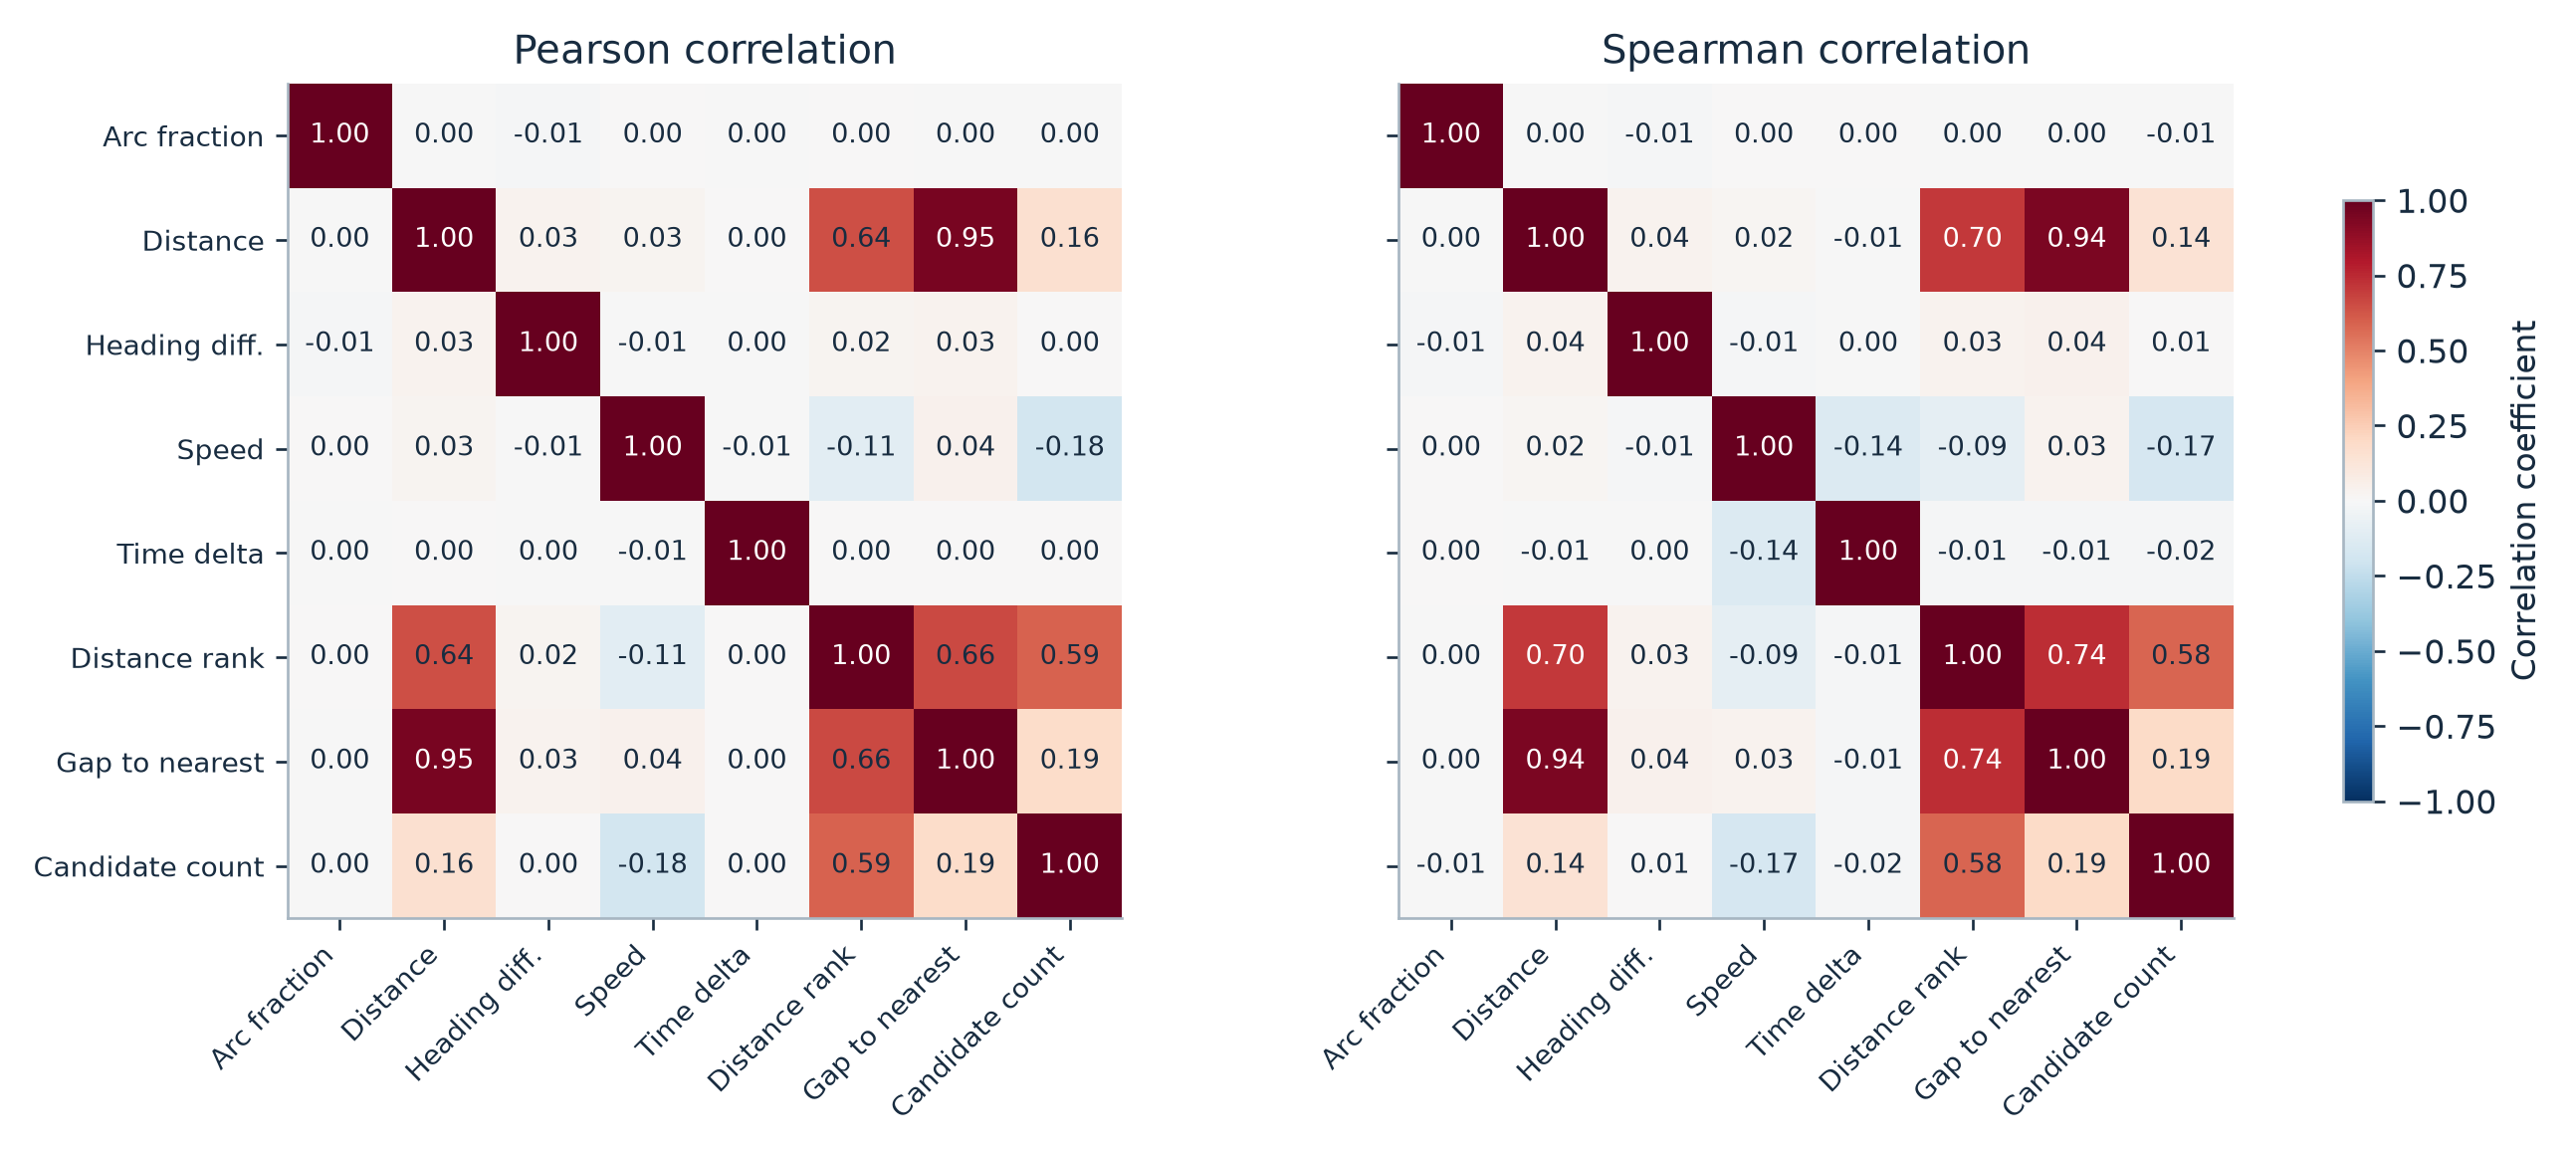

In [4]:
train_candidates = read_split("train", "candidates").sort_values([*OBS_KEY, "arc_id"], kind="stable")
train_refs = read_split("train", "references")
train_features = add_context_features(train_candidates)
features = train_features[FEATURE_ORDER]
correlations = {method: features.corr(method=method) for method in ("pearson", "spearman")}
short_names = ["Arc fraction", "Distance", "Heading diff.", "Speed", "Time delta",
               "Distance rank", "Gap to nearest", "Candidate count"]
fig, axes = plt.subplots(1, 2, figsize=(11.2, 4.65), layout="constrained", sharey=True)
for ax, (method, corr) in zip(axes, correlations.items(), strict=True):
    heat = ax.imshow(corr, vmin=-1, vmax=1, cmap="RdBu_r")
    ax.set(title=f"{method.title()} correlation", xticks=range(8), yticks=range(8))
    ax.set_xticklabels(short_names, rotation=45, ha="right", fontsize=8.5)
    ax.set_yticklabels(short_names, fontsize=8.5)
    for (row, col), value in np.ndenumerate(corr.to_numpy()):
        label = "0.00" if abs(value) < 0.005 else f"{value:.2f}"
        ax.text(col, row, label, ha="center", va="center", fontsize=8,
                color="white" if abs(value) > 0.66 else ink)
fig.colorbar(heat, ax=axes, shrink=0.72, label="Correlation coefficient")
save_figure(fig, "feature_heatmaps.png")


          rows  median_distance_m  median_heading_diff_deg  valid_heading
label                                                                    
False  1373722             31.527                   96.780        1283895
True    157540              4.749                   22.545         148576


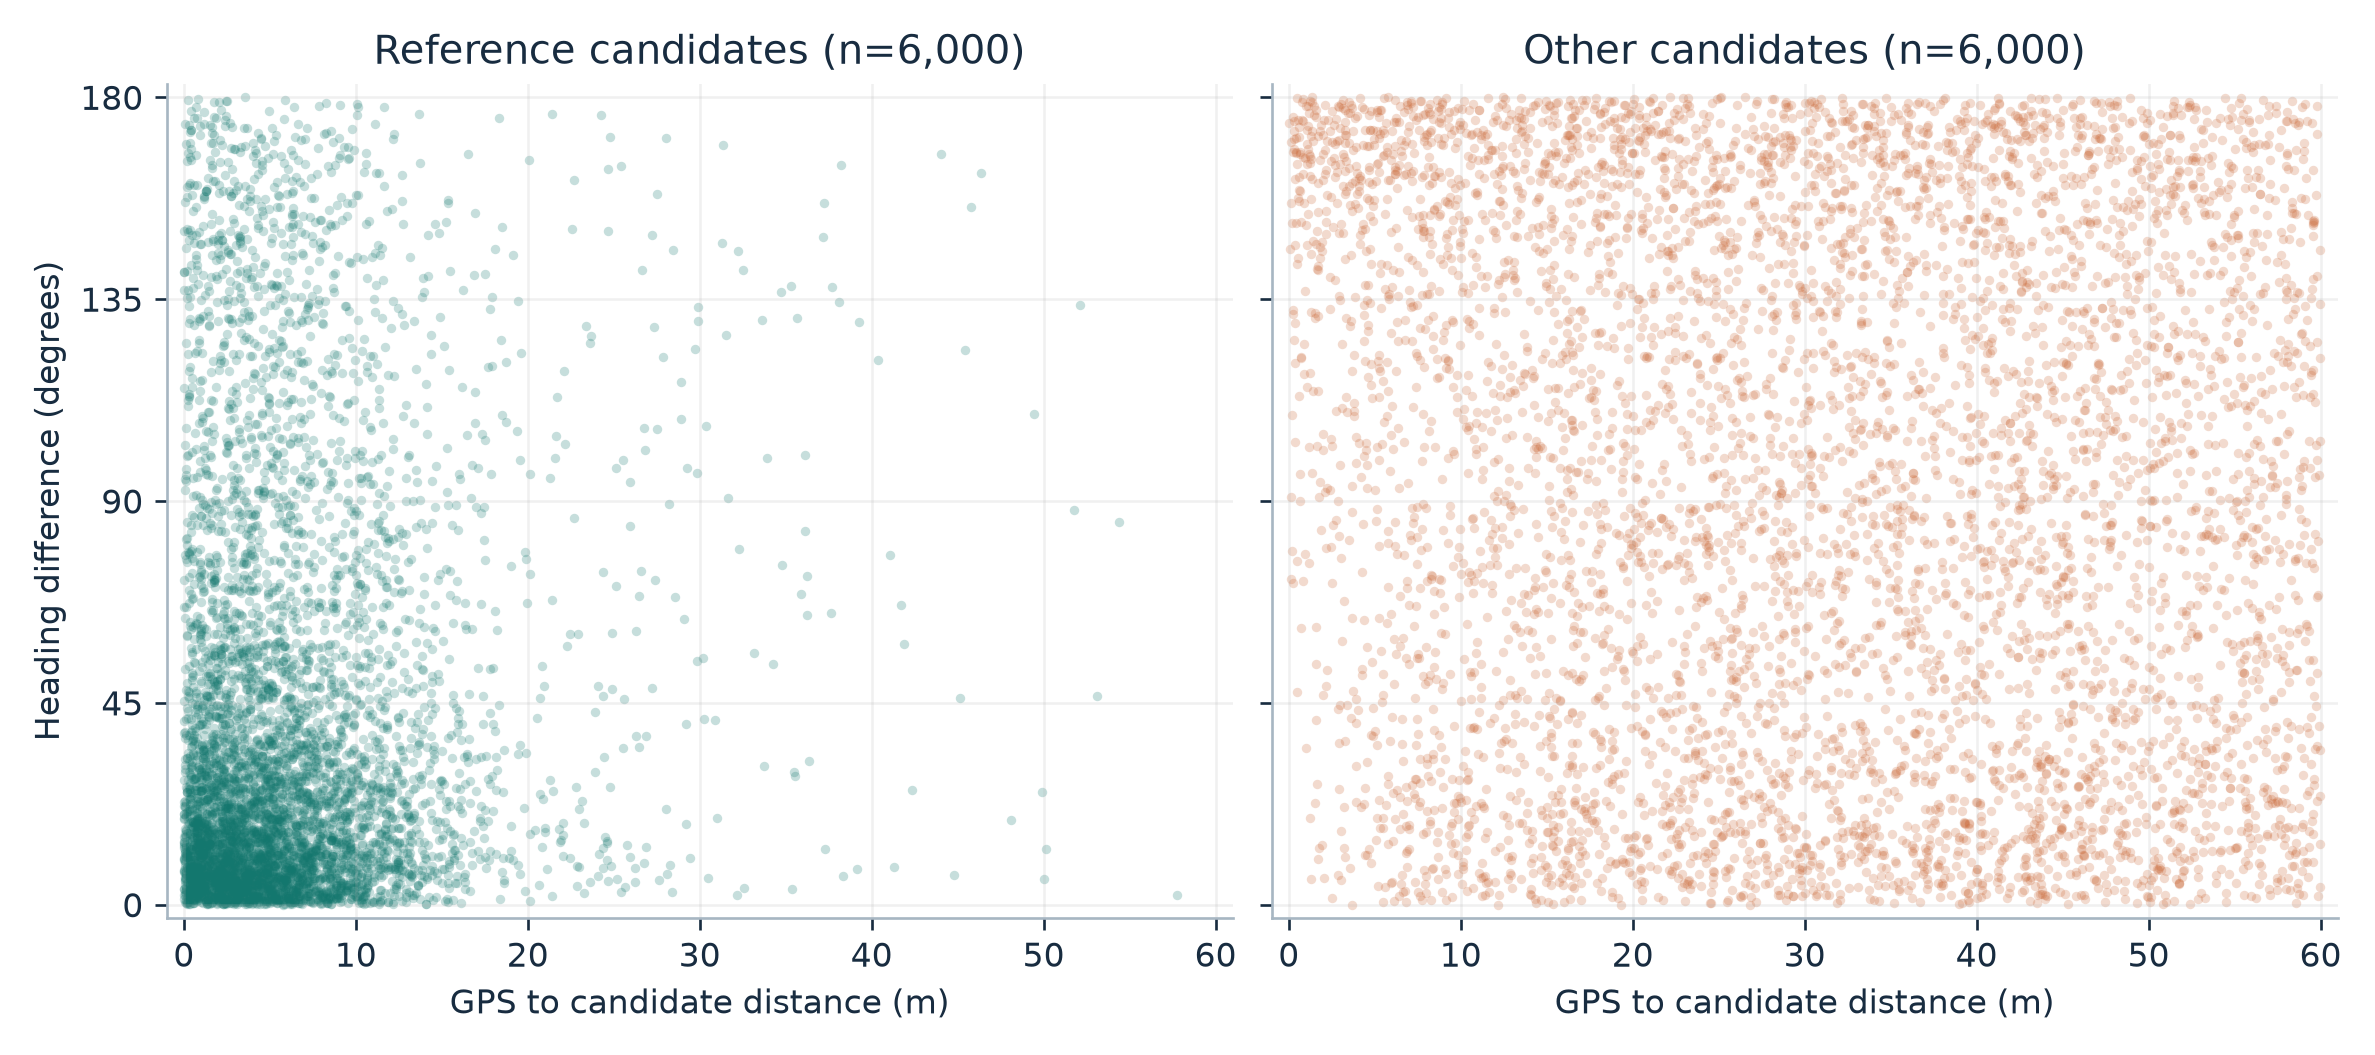

In [5]:
labelled = train_features.merge(
    train_refs.loc[train_refs["alignment_status"].eq("aligned"), [*OBS_KEY, "ref_arc_id"]],
    on=OBS_KEY, how="inner", validate="many_to_one"
)
labelled["label"] = labelled["arc_id"].eq(labelled["ref_arc_id"])
train_summary = labelled.groupby("label").agg(
    rows=("arc_id", "size"), median_distance_m=("distance_m", "median"),
    median_heading_diff_deg=("heading_diff_deg", "median"), valid_heading=("heading_diff_deg", "count")
)
print(train_summary.to_string(float_format=lambda x: f"{x:.3f}"))
fig, axes = plt.subplots(1, 2, figsize=(9.7, 4.2), layout="constrained", sharex=True, sharey=True)
for ax, (label, color, title) in zip(
    axes, [(True, teal, "Reference candidates"), (False, orange, "Other candidates")], strict=True
):
    group = labelled.loc[labelled["label"].eq(label)].dropna(subset=["heading_diff_deg"])
    sample = group.sample(n=min(6000, len(group)), random_state=42)
    ax.scatter(sample["distance_m"], sample["heading_diff_deg"], s=8, alpha=0.24,
               color=color, linewidths=0)
    ax.set(title=f"{title} (n={len(sample):,})", xlim=(-1, 61), ylim=(-3, 183),
           xlabel="GPS to candidate distance (m)", yticks=[0, 45, 90, 135, 180])
    ax.grid(alpha=0.18)
axes[0].set_ylabel("Heading difference (degrees)")
save_figure(fig, "distance_heading_scatter.png")


## Student test confusion matrix

The original experiment read a consolidated CSV. We recreate its pandas CSV write-and-read step in memory to match the float parsing used in the saved evaluation. A positive prediction means the candidate won Top-1 for its observation. An actual positive matches the independently aligned reference arc. We use the 15,979 aligned student-test observations and add one positive-only evaluation row for each reference arc missed by retrieval. Those four rows count as false negatives. The matrix uses candidate decisions, while reported Top-1 and macro F1 use observations and trip-qualified arc classes respectively.


Artifact SHA-256 84bc0aa59f22bb660ecac22536bb8f14a7fabf2ce8fc867382b642dbb34af301
n_observations         19160.000000
n_aligned              15979.000000
n_ambiguous             3160.000000
n_unaligned               21.000000
n_correct              13330.000000
top1_accuracy              0.834220
n_null_predictions         0.000000
macro_f1                   0.715544
macro_precision            0.747620
macro_recall               0.701790
n_classes               2845.000000
n_candidate_miss           4.000000
candidate_miss_rate        0.000250
log_loss_n             15975.000000
log_loss_coverage          0.999750
log_loss                   0.422145


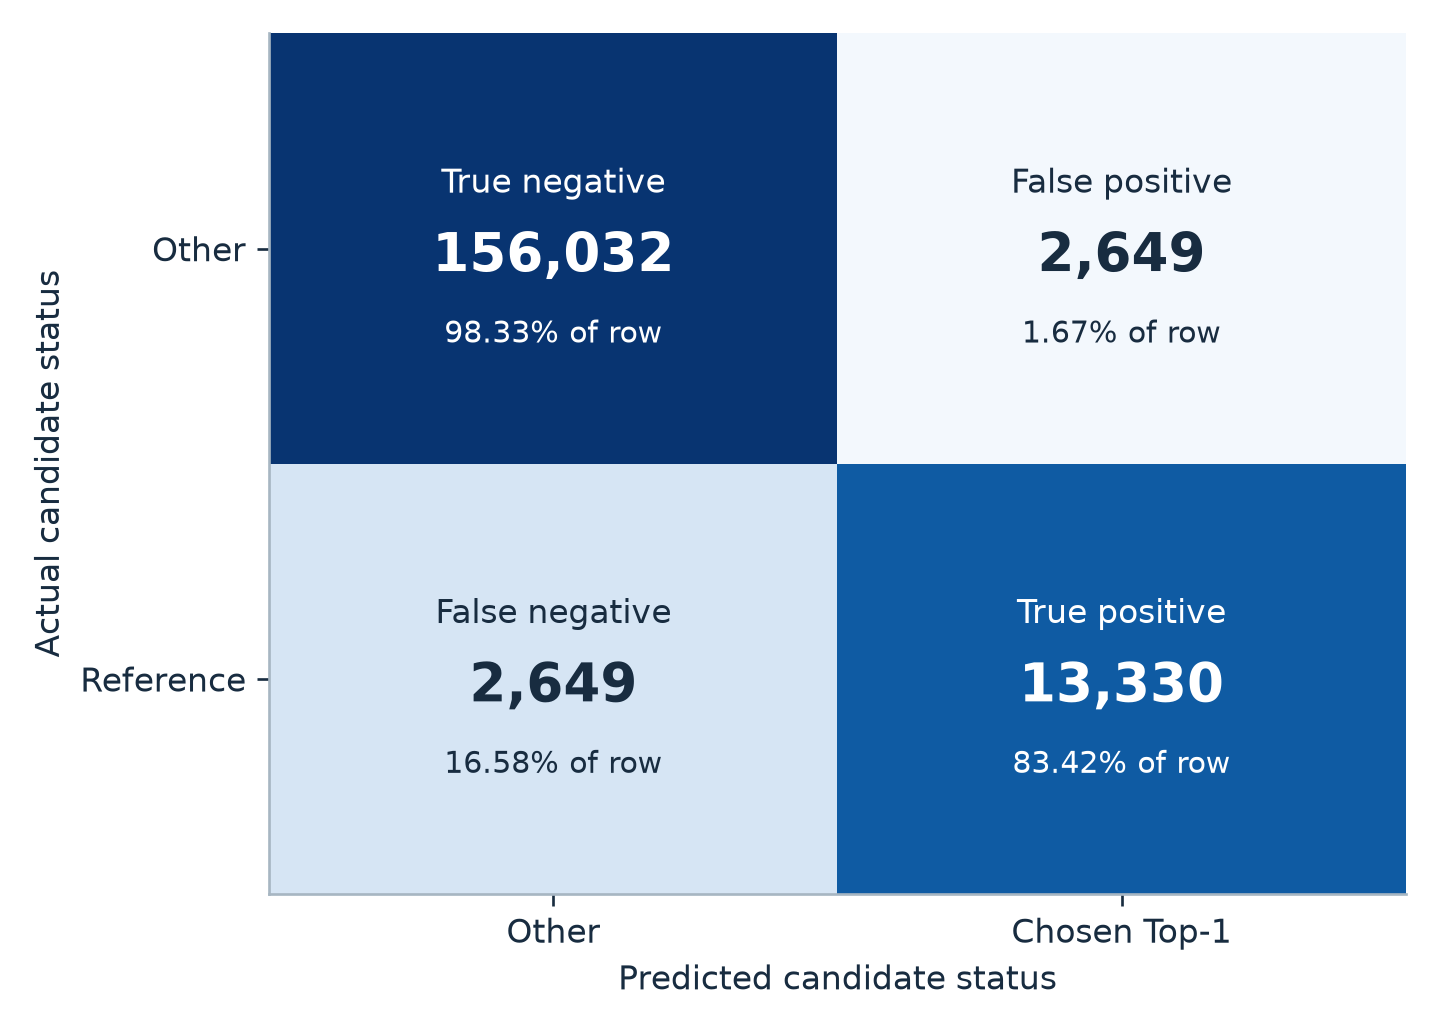

In [6]:
test_candidates = read_split("student_test", "candidates")
# Match the consolidated CSV serialization used by the training and testing notebook.
test_candidates = pd.read_csv(StringIO(test_candidates.to_csv(index=False)), dtype={"trip_id": str})
test_refs = read_split("student_test", "references")
test_tracks = []
for trip_id, group in test_refs.groupby("trip_id", sort=True):
    track_path = raw / "student_test" / trip_id / f"{trip_id}.track"
    track = pd.read_csv(track_path, sep=r"\s+", names=["lon", "lat", "time_s"])
    assert len(track) == len(group)
    test_tracks.append(track.assign(trip_id=trip_id, obs_idx=np.arange(len(track))))
test_obs = pd.concat(test_tracks, ignore_index=True)[OBSERVATION_COLS]

artifact = root / "artifacts" / "models" / "pathsnap_scorer.joblib"
artifact_sha256 = hashlib.sha256(artifact.read_bytes()).hexdigest()
scorer = CandidateScorer.load(artifact)
scored, matches = scorer.score(test_candidates, test_obs)
metrics = evaluate(test_refs, matches, test_candidates, scored)
live_csv = root / "reports" / "model-experiments" / "notebook_outputs" / "NB06_student_test_live_rescoring__all_saved_models.csv"
recorded_final = pd.read_csv(live_csv).set_index("model").loc["FINAL pathsnap_scorer"]
assert np.isclose(metrics["top1_accuracy"], recorded_final["top1"], rtol=0, atol=1e-12)
assert np.isclose(metrics["macro_f1"], recorded_final["macro_f1"], rtol=0, atol=1e-12)
assert np.isclose(metrics["log_loss"], recorded_final["log_loss"], rtol=0, atol=1e-12)

eligible = test_refs.loc[test_refs["alignment_status"].eq("aligned"), [*OBS_KEY, "ref_arc_id"]]
selected = matches.rename(columns={"arc_id": "selected_arc_id"})
audit = (test_candidates[[*OBS_KEY, "arc_id"]]
         .merge(eligible, on=OBS_KEY, validate="many_to_one")
         .merge(selected, on=OBS_KEY, how="left", validate="many_to_one"))
actual = audit["arc_id"].eq(audit["ref_arc_id"])
predicted = audit["arc_id"].eq(audit["selected_arc_id"]).fillna(False)
misses = metrics["n_candidate_miss"]
matrix = np.array([
    [(~actual & ~predicted).sum(), (~actual & predicted).sum()],
    [(actual & ~predicted).sum() + misses, (actual & predicted).sum()],
], dtype=int)
assert matrix[1].sum() == metrics["n_aligned"]
assert matrix[1, 1] == metrics["n_correct"]

fig, ax = plt.subplots(figsize=(5.8, 4.1), layout="constrained")
row_fraction = matrix / matrix.sum(axis=1, keepdims=True)
ax.imshow(row_fraction, vmin=0, vmax=1, cmap="Blues", aspect="auto")
ax.set(xticks=[0, 1], yticks=[0, 1], xticklabels=["Other", "Chosen Top-1"],
       yticklabels=["Other", "Reference"], xlabel="Predicted candidate status",
       ylabel="Actual candidate status")
for (row, col), count in np.ndenumerate(matrix):
    fraction = row_fraction[row, col]
    cell_name = [["True negative", "False positive"], ["False negative", "True positive"]][row][col]
    color = "white" if fraction > 0.55 else ink
    ax.text(col, row - 0.15, cell_name, color=color, ha="center", va="center", fontsize=10)
    ax.text(col, row + 0.02, f"{count:,}", color=color, ha="center", va="center",
            fontweight="bold", fontsize=16)
    ax.text(col, row + 0.20, f"{fraction:.2%} of row", color=color, ha="center", va="center", fontsize=9)
save_figure(fig, "confusion_matrix.png")
print(f"Artifact SHA-256 {artifact_sha256}")
print(pd.Series(metrics).to_string())


## Optuna trial history

The curves use the archived 20 trials per model. Horizontal dashed lines show each model's untuned score. The solid curves track the best grouped cross-validation macro F1 reached so far.


LightGBM ranker best at trial 6 with macro F1 0.72220883
CatBoost best at trial 14 with macro F1 0.71553474


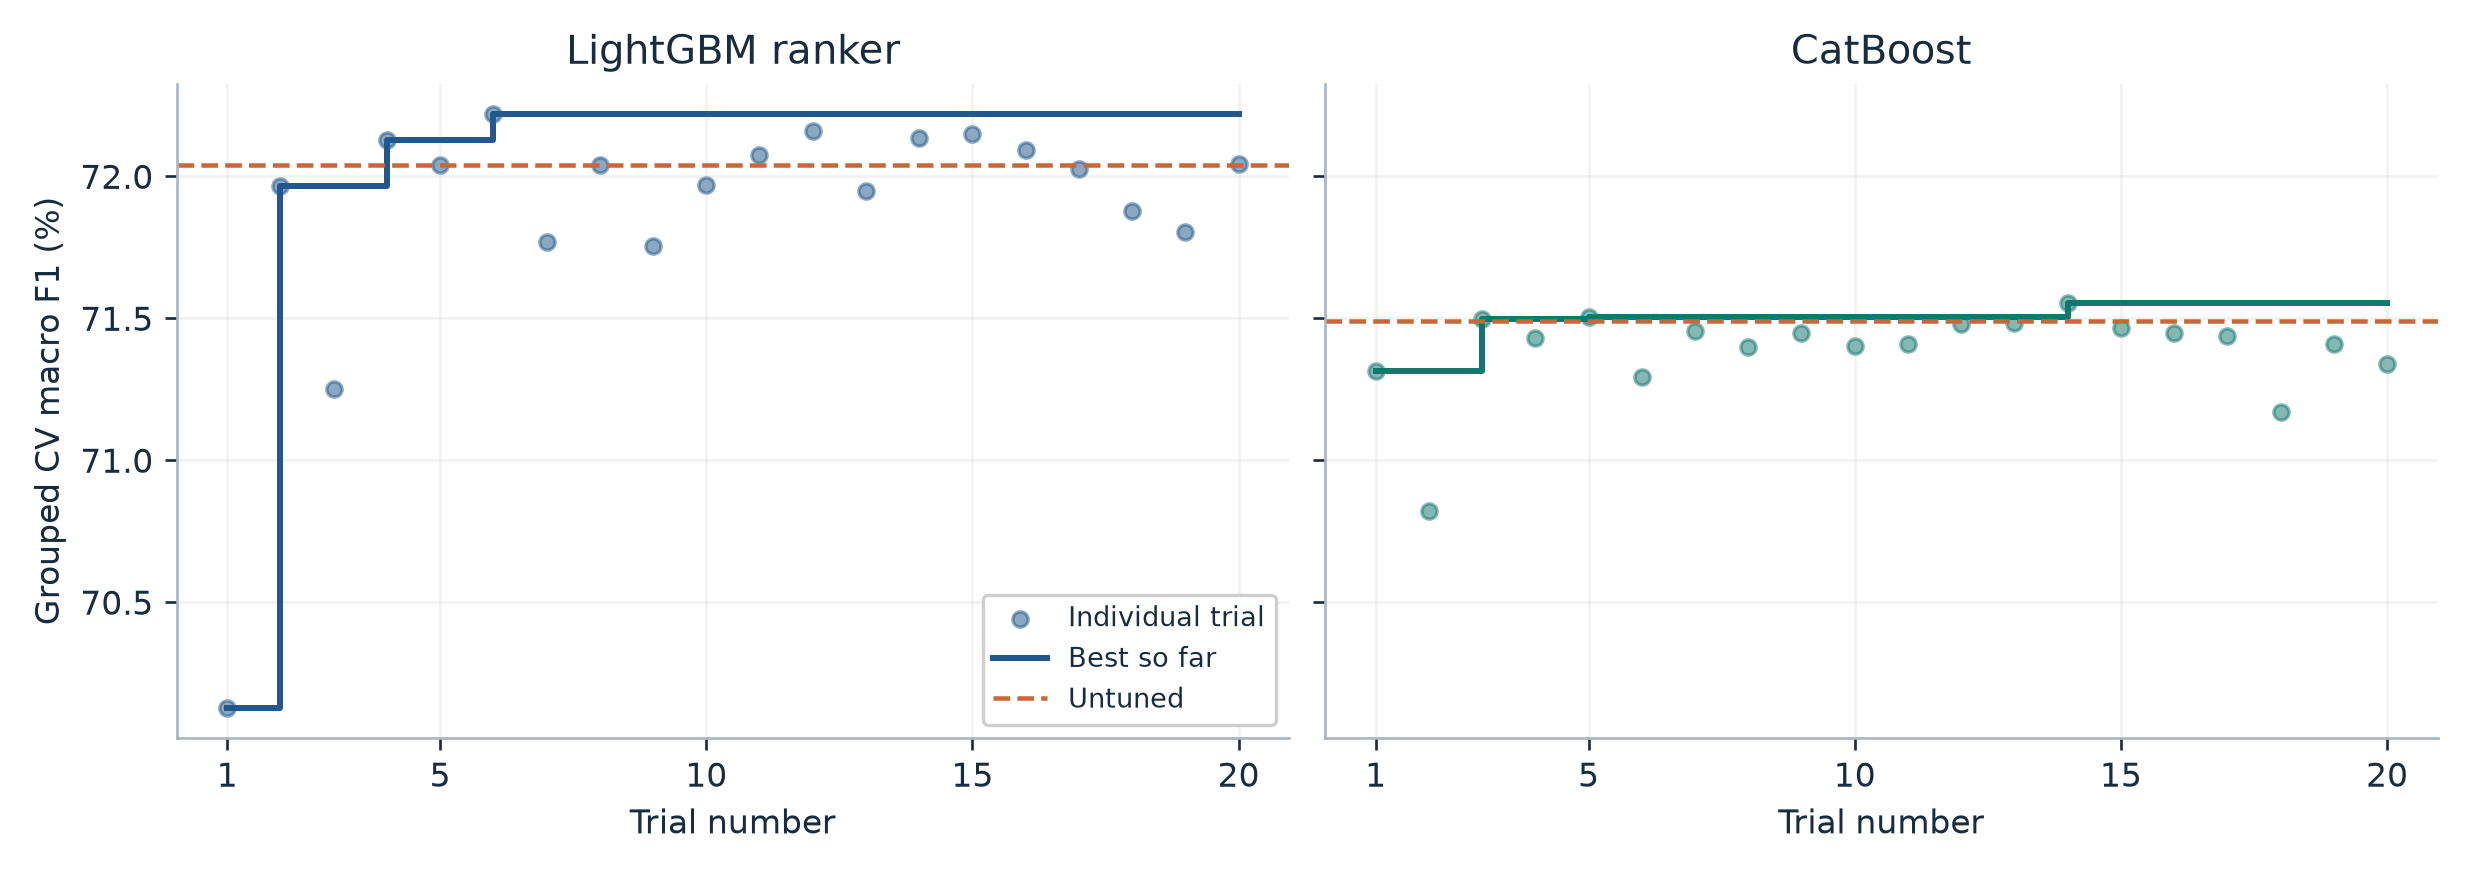

In [7]:
stage3 = archive / "03_bayesian_tuning_lightgbm_ranker_and_catboost"
leaderboard = pd.read_csv(next((archive / "04_final_model_selection").glob("*leaderboard*.csv")))
fig, axes = plt.subplots(1, 2, figsize=(10.1, 3.45), layout="constrained", sharey=True)
for ax, (name, label, color) in zip(
        axes, [("lightgbm_ranker", "LightGBM ranker", blue), ("catboost", "CatBoost", teal)], strict=True
):
    history = pd.read_csv(next(stage3.glob(f"*trial_history__{name}__*.csv"))).sort_values("number")
    baseline = leaderboard.loc[leaderboard["model"].eq(name), "cv_macro_f1_mean"].iat[0]
    assert len(history) == 20 and history["state"].eq("COMPLETE").all()
    trial_no = history["number"] + 1
    ax.scatter(trial_no, 100 * history["value"], color=color, alpha=0.52, s=21, label="Individual trial")
    ax.step(trial_no, 100 * history["value"].cummax(), where="post", color=color, lw=1.8, label="Best so far")
    ax.axhline(100 * baseline, color=orange, ls="--", lw=1.35, label="Untuned")
    ax.set(title=label, xlabel="Trial number", xticks=[1, 5, 10, 15, 20])
    ax.grid(alpha=0.16)
    best = history.loc[history["value"].idxmax()]
    print(f"{label} best at trial {int(best['number']) + 1} with macro F1 {best['value']:.8f}")
axes[0].set_ylabel("Grouped CV macro F1 (%)")
axes[0].legend(loc="lower right", fontsize=8, framealpha=0.96)
save_figure(fig, "tuning_history.png")
